# Exercice 3 — Recherche d'images par les caractéristiques de Tamura

## Objectif

Extraire les **quatre caractéristiques de Tamura** de chaque image du dossier `seance 4/Texture/Texture/` (38 images), les enregistrer dans un **fichier JSON** par image, puis construire un **système de recherche d'images par similarité** qui retourne les 5 images les plus proches d'une image requête.

## Les quatre caractéristiques

| Caractéristique | Ce qu'elle mesure | Intuition |
|---|---|---|
| **Rudesse** (coarseness) | La taille des éléments de texture | Une texture de sable est fine, une texture de briques est grossière |
| **Contraste** (contrast) | L'écart d'intensité entre les pixels | Une texture très marquée a un contraste élevé |
| **Directionnalité** (directionality) | La présence d'orientations privilégiées | Des rayures verticales sont très directionnelles, du bruit ne l'est pas |
| **Granularité** (granularity) | La taille moyenne des grains | Une texture de gravier a des grains plus gros que du sable fin |

## Différence avec les exercices 1 et 2

Les exercices 1 et 2 décrivaient la **couleur**. Ici, on décrit la **texture** : la répartition spatiale des intensités. Les images sont d'ailleurs converties en **niveaux de gris**, car la texture est une propriété d'intensité, pas de couleur.

## Plan du notebook

| Étape | Contenu |
|---|---|
| 1 | Chargement des images en niveaux de gris |
| 2 | Rudesse (coarseness) |
| 3 | Contraste |
| 4 | Directionnalité |
| 5 | Granularité |
| 6 | Vecteur de caractéristiques et normalisation |
| 7 | Génération des fichiers JSON |
| 8 | Recherche par similarité (top 5) |
| 9 | Visualisation des résultats |
| 10 | Analyse et discussion |


In [1]:
import os
import glob
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
# Le notebook fonctionne que le dossier courant soit "seance 4" ou la racine.
BASE = "seance 4" if os.path.isdir("seance 4") else "."

DOSSIER_TEXTURES = os.path.join(BASE, "Texture", "Texture")
DOSSIER_RESULTATS = os.path.join(BASE, "resultats")
DOSSIER_JSON = os.path.join(DOSSIER_RESULTATS, "json")
DOSSIER_RECHERCHE = os.path.join(DOSSIER_RESULTATS, "ex3_recherche")

os.makedirs(DOSSIER_JSON, exist_ok=True)
os.makedirs(DOSSIER_RECHERCHE, exist_ok=True)

# Paramètres de la méthode
NB_ECHELLES = 5     # échelles k = 0..4 -> fenêtres 1, 2, 4, 8, 16
NB_BINS_DIR = 16    # nombre de bins de l'histogramme d'orientations

# Liste des images
chemins = sorted(glob.glob(os.path.join(DOSSIER_TEXTURES, "*.jpg")))
noms_images = [os.path.basename(c) for c in chemins]

print(f"{len(chemins)} images trouvées dans '{DOSSIER_TEXTURES}'.")
print(f"Premières images : {', '.join(noms_images[:5])} ...")


38 images trouvées dans '.\Texture\Texture'.
Premières images : Im01.jpg, Im02.jpg, Im03.jpg, Im04.jpg, Im05.jpg ...


## Étape 1 — Chargement des images en niveaux de gris

Les caractéristiques de Tamura décrivent la **texture**, c'est-à-dire la variation spatiale de l'intensité lumineuse. On travaille donc sur l'image **en niveaux de gris**, et non sur les trois canaux RGB.

### Précisions sur le prétraitement

- **Dimensions originales conservées** : les images vont de 311×356 à 640×515. On ne les redimensionne pas, car les caractéristiques de Tamura sont exprimées en **pixels** et un redimensionnement modifierait la rudesse et la granularité.
- **Aucun masque de fond** : contrairement aux exercices 1 et 2, les images de texture occupent **toute la surface** de l'image. Il n'y a pas d'objet sur fond uniforme à isoler.
- **Conversion en `float64`** : nécessaire pour les calculs de moyennes et de variance sans perte de précision.


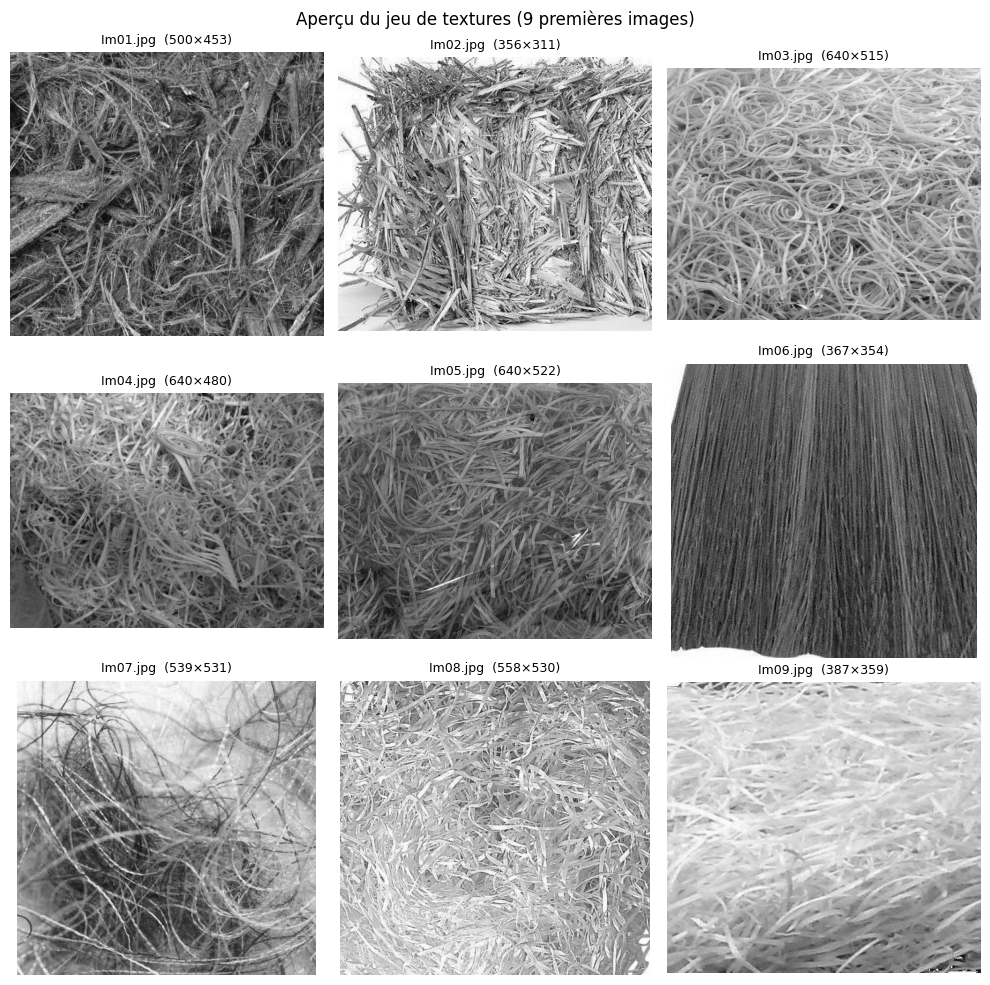

Dimensions : de (311, 356) à (640, 480) (hauteur, largeur)


In [2]:
def charger_gris(chemin):
    """Charge une image et la convertit en niveaux de gris (float64)."""
    bgr = cv2.imread(chemin)
    if bgr is None:
        raise FileNotFoundError(f"Image introuvable : {chemin}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)


# --- Aperçu du jeu de données : 9 premières images ---
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, chemin in zip(axes.ravel(), chemins[:9]):
    gris = charger_gris(chemin)
    ax.imshow(gris, cmap="gray")
    h, w = gris.shape
    ax.set_title(f"{os.path.basename(chemin)}  ({w}×{h})", fontsize=9)
    ax.axis("off")

plt.suptitle("Aperçu du jeu de textures (9 premières images)")
plt.tight_layout()
plt.show()

# Dimensions de toutes les images
dimensions = [charger_gris(c).shape for c in chemins]
print(f"Dimensions : de {min(dimensions)} à {max(dimensions)} (hauteur, largeur)")


## Étape 2 — Rudesse (Coarseness)

### Principe

La **rudesse** mesure la **taille des éléments** qui composent la texture. Une texture de briques (grands éléments) est grossière ; une texture de sable (petits éléments) est fine.

### Méthode de Tamura

Pour chaque échelle $k$ (fenêtre $2^k \times 2^k$, de $1\times1$ à $16\times16$), on calcule l'image des **moyennes locales** $A_k(x,y)$. Puis on mesure la différence entre les moyennes de deux échelles successives :

$$S_{\text{best}}(x,y) = \max_{k} \left| A_k(x,y) - A_{k+1}(x,y) \right|$$

La rudesse globale est la moyenne de cette réponse sur toute l'image :

$$F_{\text{crs}} = \frac{1}{M \cdot N} \sum_{x,y} S_{\text{best}}(x,y)$$

### Interprétation

- Un **grand** $F_{\text{crs}}$ signifie que les différences de moyennes persistent à grande échelle → texture **grossière**.
- Un **petit** $F_{\text{crs}}$ signifie que les différences disparaissent dès les petites échelles → texture **fine**.

La fonction `cv2.blur` réalise une moyenne glissante sur une fenêtre carrée, ce qui correspond exactement à $A_k$.


In [3]:
def moyennes_echelles(gris, nb_echelles=NB_ECHELLES):
    """Calcule les images de moyennes locales A_k pour k = 0..nb_echelles.

    A_k est obtenue par une moyenne glissante sur une fenêtre 2^k x 2^k.
    """
    return [cv2.blur(gris, (2 ** k, 2 ** k)) for k in range(nb_echelles + 1)]


def tamura_rudesse(gris, nb_echelles=NB_ECHELLES):
    """Rudesse de Tamura : moyenne du maximum des |A_k - A_{k+1}| sur k."""
    moyennes = moyennes_echelles(gris, nb_echelles)

    # Pour chaque échelle, différence entre moyennes de deux échelles successives
    differences = [np.abs(moyennes[k] - moyennes[k + 1]) for k in range(nb_echelles)]

    # S_best(x, y) = max sur k de la différence
    s_best = np.maximum.reduce(differences)

    # Moyenne sur toute l'image
    return float(s_best.mean())


# --- Test sur les 5 premières images ---
print(f"{'Image':10s} {'Rudesse':>10s}")
print("-" * 22)
for chemin in chemins[:5]:
    gris = charger_gris(chemin)
    print(f"{os.path.basename(chemin):10s} {tamura_rudesse(gris):10.3f}")


Image         Rudesse
----------------------
Im01.jpg       16.272
Im02.jpg       26.845
Im03.jpg       11.685
Im04.jpg       11.330
Im05.jpg       13.693


## Étape 3 — Contraste

### Principe

Le **contraste** mesure l'**écart d'intensité** entre les pixels : une texture très marquée (fort contraste) se distingue nettement, une texture douce se distingue peu.

### Méthode de Tamura

Tamura combine l'écart-type $\sigma$ et le **kurtosis** $\alpha_4$ :

$$F_{\text{con}} = \frac{\sigma}{\alpha_4^{1/4}} \quad \text{avec} \quad \alpha_4 = \frac{\mu_4}{\sigma^4}$$

où $\mu_4$ est le moment centré d'ordre 4 :

$$\mu_4 = \frac{1}{MN}\sum_{x,y} \left(I(x,y) - \bar{I}\right)^4$$

### Pourquoi diviser par $\alpha_4^{1/4}$ ?

Le kurtosis mesure la « forme » de la distribution des intensités :

- une distribution **piquée** (peu de valeurs extrêmes) donne un $\alpha_4$ élevé → le contraste est **atténué** ;
- une distribution **étalée** donne un $\alpha_4$ faible → le contraste est **renforcé**.

Ce terme évite qu'une image avec quelques pixels très brillants (reflets) soit jugée à tort très contrastée.


In [4]:
def tamura_contraste(gris):
    """Contraste de Tamura : sigma / alpha4^(1/4), avec alpha4 = kurtosis."""
    ecart_type = gris.std()

    # Image uniforme : pas de contraste (évite la division par zéro)
    if ecart_type == 0:
        return 0.0

    # Moment centré d'ordre 4
    moyenne = gris.mean()
    moment_4 = np.mean((gris - moyenne) ** 4)

    # Kurtosis
    alpha_4 = moment_4 / (ecart_type ** 4)

    return float(ecart_type / (alpha_4 ** 0.25))


# --- Test sur les 5 premières images ---
print(f"{'Image':10s} {'Contraste':>10s}")
print("-" * 22)
for chemin in chemins[:5]:
    gris = charger_gris(chemin)
    print(f"{os.path.basename(chemin):10s} {tamura_contraste(gris):10.3f}")


Image       Contraste
----------------------
Im01.jpg       25.443
Im02.jpg       43.264
Im03.jpg       21.834
Im04.jpg       25.023
Im05.jpg       23.640


## Étape 4 — Directionnalité

### Principe

La **directionnalité** mesure la présence d'**orientations privilégiées** dans la texture. Des rayures verticales régulières sont très directionnelles ; du foin enchevêtré ne l'est pas du tout.

### Méthode

1. On calcule le **gradient** de l'image avec Sobel (dérivée horizontale $g_x$ et verticale $g_y$).
2. Pour chaque pixel, on en déduit :
   - la **magnitude** $\|g\| = \sqrt{g_x^2 + g_y^2}$ (force du contour) ;
   - l'**orientation** $\theta = \arctan(g_y / g_x)$, ramenée dans $[0, \pi)$ car une texture est symétrique par rotation de 180°.
3. On construit un **histogramme des orientations**, pondéré par la magnitude : un contour fort pèse plus qu'un contour faible.
4. On normalise l'histogramme, puis on mesure sa **concentration**.

### Mesure de concentration retenue

Tamura propose de détecter les pics de l'histogramme et de mesurer leur dispersion. Sur ce jeu d'images, cette approche s'est révélée **peu fiable** : l'histogramme est périodique, et le pic d'une texture à rayures horizontales se retrouve à la fois au bin 0 et au bin 15 (angle 0 et angle proche de $\pi$ représentent la même orientation). Le pic est alors compté deux fois et la formule devient incohérente (elle peut même donner une valeur négative).

Nous utilisons donc une mesure équivalente mais plus robuste, fondée sur l'**entropie** de l'histogramme :

$$H(\phi) = -\sum_{i=1}^{n} p_i \log p_i \qquad F_{\text{dir}} = 1 - \frac{H(\phi)}{\log n}$$

où $p_i$ est la proportion du bin $i$ et $n$ le nombre de bins.

### Interprétation

- $F_{\text{dir}}$ proche de **1** : l'histogramme est **concentré** sur une seule orientation → texture fortement directionnelle.
- $F_{\text{dir}}$ proche de **0** : l'histogramme est **uniforme** → texture isotrope (pas d'orientation privilégiée).

L'entropie est une mesure classique de concentration et elle est **insensible au caractère circulaire** de l'histogramme, ce qui évite le problème du double comptage du pic.


In [12]:
def histogramme_orientations(gris, nb_bins=NB_BINS_DIR):
    """Histogramme normalisé des orientations, pondéré par la magnitude du gradient."""
    # Gradient de Sobel
    gx = cv2.Sobel(gris, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gris, cv2.CV_64F, 0, 1, ksize=3)

    magnitude = np.hypot(gx, gy)

    # Orientation dans [0, pi) : une texture est symétrique par rotation de 180°
    orientation = (np.arctan2(gy, gx) + np.pi) % np.pi

    # Histogramme pondéré par la magnitude
    hist, _ = np.histogram(orientation, bins=nb_bins, range=(0, np.pi),
                           weights=magnitude)

    total = hist.sum()
    if total > 0:
        hist = hist / total
    return hist


def tamura_directionnalite(gris, nb_bins=NB_BINS_DIR):
    """Directionnalité de Tamura : concentration de l'histogramme des orientations.

    On utilise 1 - entropie normalisée, qui mesure la concentration de
    l'histogramme : 1 = une seule orientation, 0 = orientations uniformes.
    """
    hist = histogramme_orientations(gris, nb_bins)

    # Bins non vides uniquement (log(0) n'est pas défini)
    proportions = hist[hist > 0]
    if len(proportions) == 0:
        return 0.0

    # Entropie normalisée dans [0, 1]
    entropie = -np.sum(proportions * np.log(proportions)) / np.log(nb_bins)

    # Directionnalité = concentration
    return float(1.0 - entropie)


# --- Test sur les 5 premières images ---
print(f"{'Image':10s} {'Directionnalité':>16s}")
print("-" * 28)
for chemin in chemins[:5]:
    gris = charger_gris(chemin)
    print(f"{os.path.basename(chemin):10s} {tamura_directionnalite(gris):16.3f}")


Image       Directionnalité
----------------------------
Im01.jpg              0.004
Im02.jpg              0.006
Im03.jpg              0.015
Im04.jpg              0.001
Im05.jpg              0.008


## Étape 5 — Granularité

### Précision importante sur cette caractéristique

Tamura a défini **six** caractéristiques, mais la **granularité n'est pas une caractéristique canonique** au sens strict : elle n'a pas de formule universellement admise et est souvent omise des implémentations.

Dans ce TP, nous adoptons donc une **définition opérationnelle**, cohérente avec le calcul de la rudesse :

> La granularité est la **taille moyenne des grains** de la texture, obtenue en moyennant les échelles $2^k$ pondérées par leur contribution à la réponse de rudesse.

### Formule

Pour chaque échelle $k$, on calcule la contribution moyenne $c_k = \overline{\left|A_k - A_{k+1}\right|}$ (la même quantité que dans la rudesse). Les poids sont les contributions normalisées :

$$w_k = \frac{c_k}{\sum_j c_j} \qquad F_{\text{gran}} = \sum_k w_k \cdot 2^k$$

### Pourquoi une moyenne pondérée plutôt qu'un simple argmax ?

L'argmax ne prend que **quatre valeurs distinctes** sur ce jeu d'images (1, 4, 8, 16), ce qui est trop grossier pour discriminer 38 textures. La moyenne pondérée donne une valeur **continue** qui reflète l'ensemble du profil d'échelles.

### Interprétation

- $F_{\text{gran}}$ **proche de 1** : les grains sont petits (texture fine).
- $F_{\text{gran}}$ **proche de 16** : les grains sont grands (texture grossière).


In [6]:
def tamura_granularite(gris, nb_echelles=NB_ECHELLES):
    """Granularité (définition opérationnelle) : taille moyenne des grains.

    Moyenne des échelles 2^k pondérée par la contribution de chaque échelle
    à la réponse de rudesse.
    """
    moyennes = moyennes_echelles(gris, nb_echelles)

    # Contribution de chaque échelle (même quantité que dans la rudesse)
    contributions = np.array([
        np.abs(moyennes[k] - moyennes[k + 1]).mean() for k in range(nb_echelles)
    ])

    # Texture parfaitement uniforme : aucune échelle ne domine
    if contributions.sum() == 0:
        return 0.0

    # Poids normalisés et tailles des fenêtres
    poids = contributions / contributions.sum()
    tailles = np.array([2.0 ** k for k in range(nb_echelles)])

    return float(np.sum(poids * tailles))


# --- Test sur les 5 premières images ---
print(f"{'Image':10s} {'Granularité':>13s}")
print("-" * 25)
for chemin in chemins[:5]:
    gris = charger_gris(chemin)
    print(f"{os.path.basename(chemin):10s} {tamura_granularite(gris):13.3f}")


Image        Granularité
-------------------------
Im01.jpg           5.719
Im02.jpg           5.010
Im03.jpg           6.600
Im04.jpg           6.587
Im05.jpg           5.918


## Étape 6 — Vecteur de caractéristiques et normalisation

### Le vecteur de caractéristiques

Chaque image est décrite par un vecteur de **quatre valeurs brutes** :

$$\mathbf{v} = \left[\, F_{\text{crs}},\; F_{\text{con}},\; F_{\text{dir}},\; F_{\text{gran}} \,\right]$$

### Le problème des échelles

Les quatre caractéristiques n'ont **pas du tout la même amplitude** sur ce jeu d'images :

| Caractéristique | Ordre de grandeur | Écart-type |
|---|---|---|
| Rudesse | ~4 à 27 | ~6 |
| Contraste | ~14 à 48 | ~9 |
| Directionnalité | 0 à 1 | ~0.3 |
| Granularité | ~3.6 à 8.7 | ~1.4 |

Si l'on calcule directement une distance euclidienne, la **rudesse et le contraste écrasent complètement** la directionnalité et la granularité : deux images très différentes en directionnalité mais proches en rudesse seraient jugées identiques.

### Solution : normalisation z-score

On centre et réduit chaque caractéristique sur l'ensemble du dossier :

$$z = \frac{x - \mu}{\sigma}$$

où $\mu$ et $\sigma$ sont la moyenne et l'écart-type de la caractéristique **sur les 38 images**.

**Précaution** : si $\sigma = 0$ (caractéristique constante, ce qui n'arrive pas ici mais pourrait arriver sur un autre jeu), on utilise $\sigma = 1$ pour éviter une division par zéro.

### Ce qui est conservé dans les JSON

Conformément à la consigne, les fichiers JSON contiennent les **caractéristiques brutes**. La normalisation z-score n'est appliquée **que pour la comparaison**, car elle dépend du jeu d'images complet.


In [13]:
NOMS_CARACTERISTIQUES = ["rudesse", "contraste", "directionnalite", "granularite"]


def vecteur_tamura(gris):
    """Vecteur brut des 4 caractéristiques de Tamura d'une image en gris."""
    return [
        tamura_rudesse(gris),
        tamura_contraste(gris),
        tamura_directionnalite(gris),
        tamura_granularite(gris),
    ]


# --- Calcul des caractéristiques brutes pour les 38 images ---
caracteristiques_brutes = []
for chemin in chemins:
    gris = charger_gris(chemin)
    caracteristiques_brutes.append(vecteur_tamura(gris))

caracteristiques_brutes = np.array(caracteristiques_brutes)
print(f"Matrice de caractéristiques : {caracteristiques_brutes.shape} "
      f"({len(chemins)} images x 4 caractéristiques)\n")

# --- Affichage des 10 premières images ---
print(f"{'Image':10s} {'Rudesse':>9s} {'Contraste':>10s} {'Direction.':>11s} {'Granular.':>10s}")
print("-" * 54)
for nom, valeurs in zip(noms_images[:10], caracteristiques_brutes[:10]):
    print(f"{nom:10s} {valeurs[0]:9.3f} {valeurs[1]:10.3f} {valeurs[2]:11.3f} {valeurs[3]:10.3f}")
print("   ...")

# --- Statistiques du jeu de données ---
moyennes = caracteristiques_brutes.mean(axis=0)
ecarts_types = caracteristiques_brutes.std(axis=0)

print(f"\n{'Caractéristique':16s} {'min':>8s} {'max':>8s} {'moyenne':>9s} {'écart-type':>11s}")
print("-" * 56)
for nom, i in zip(NOMS_CARACTERISTIQUES, range(4)):
    colonne = caracteristiques_brutes[:, i]
    print(f"{nom:16s} {colonne.min():8.3f} {colonne.max():8.3f} "
          f"{moyennes[i]:9.3f} {ecarts_types[i]:11.3f}")


Matrice de caractéristiques : (38, 4) (38 images x 4 caractéristiques)

Image        Rudesse  Contraste  Direction.  Granular.
------------------------------------------------------
Im01.jpg      16.272     25.443       0.004      5.719
Im02.jpg      26.845     43.264       0.006      5.010
Im03.jpg      11.685     21.834       0.015      6.600
Im04.jpg      11.330     25.023       0.001      6.587
Im05.jpg      13.693     23.640       0.008      5.918
Im06.jpg      14.344     16.607       0.206      4.833
Im07.jpg      13.522     43.097       0.004      6.521
Im08.jpg      21.445     30.746       0.002      4.695
Im09.jpg       9.435     26.243       0.068      6.315
Im10.jpg       7.045     17.276       0.007      8.189
   ...

Caractéristique       min      max   moyenne  écart-type
--------------------------------------------------------
rudesse             4.219   26.845    14.445       6.033
contraste          13.616   47.874    27.293       8.822
directionnalite     0.000    0.4

## Étape 7 — Génération des fichiers JSON

### Format demandé

Un fichier JSON par image, portant le **même radical** que l'image :

| Image | Fichier JSON |
|---|---|
| `Im01.jpg` | `Im01.json` |
| `Im02.jpg` | `Im02.json` |
| … | … |
| `Im38.jpg` | `Im38.json` |

### Emplacement

Les fichiers sont enregistrés dans **`seance 4/resultats/json/`**. Le dossier `Texture/Texture/` reste ainsi propre, avec uniquement les images originales.

### Contenu d'un fichier

```json
{
  "image": "Im01.jpg",
  "caracteristiques": {
    "rudesse": 16.27,
    "contraste": 25.44,
    "directionnalite": 0.014,
    "granularite": 5.72
  }
}
```

Conformément à la consigne, on enregistre les **valeurs brutes** (pas les valeurs normalisées, qui dépendent du jeu d'images complet).


In [14]:
# --- Écriture d'un JSON par image ---
for nom, valeurs in zip(noms_images, caracteristiques_brutes):
    radical = os.path.splitext(nom)[0]          # "Im01.jpg" -> "Im01"
    chemin_json = os.path.join(DOSSIER_JSON, radical + ".json")

    contenu = {
        "image": nom,
        "caracteristiques": {
            nom_carac: round(float(valeur), 6)
            for nom_carac, valeur in zip(NOMS_CARACTERISTIQUES, valeurs)
        },
    }

    with open(chemin_json, "w", encoding="utf-8") as f:
        json.dump(contenu, f, indent=2, ensure_ascii=False)

print(f"{len(noms_images)} fichiers JSON écrits dans '{DOSSIER_JSON}'.\n")

# --- Vérification : relecture d'un fichier ---
chemin_verif = os.path.join(DOSSIER_JSON, "Im01.json")
with open(chemin_verif, encoding="utf-8") as f:
    contenu_verif = json.load(f)

print(f"Vérification de '{os.path.basename(chemin_verif)}' :")
print(json.dumps(contenu_verif, indent=2, ensure_ascii=False))

# --- Liste des fichiers créés ---
fichiers_json = sorted(glob.glob(os.path.join(DOSSIER_JSON, "*.json")))
print(f"\n{len(fichiers_json)} fichiers présents : "
      f"{', '.join(os.path.basename(x) for x in fichiers_json[:5])} ...")


38 fichiers JSON écrits dans '.\resultats\json'.

Vérification de 'Im01.json' :
{
  "image": "Im01.jpg",
  "caracteristiques": {
    "rudesse": 16.272292,
    "contraste": 25.442655,
    "directionnalite": 0.003931,
    "granularite": 5.718663
  }
}

38 fichiers présents : Im01.json, Im02.json, Im03.json, Im04.json, Im05.json ...


## Étape 8 — Recherche par similarité

### Principe

1. On choisit une **image requête**.
2. On calcule son vecteur de caractéristiques (déjà fait à l'étape 6).
3. On **normalise** tous les vecteurs (z-score sur les 38 images).
4. On calcule la **distance euclidienne** entre la requête et chacune des 37 autres images.
5. On trie par distance croissante et on retourne les **5 plus proches**.

### Points importants

- **L'image requête est exclue** des résultats (sa distance à elle-même vaut 0 et occuperait la première place inutilement).
- La **normalisation z-score** est indispensable : sans elle, la rudesse et le contraste domineraient totalement la distance.
- La distance est calculée sur les vecteurs **normalisés**, mais les JSON contiennent les valeurs **brutes**.

### Formule

$$d(\mathbf{z}_q, \mathbf{z}_i) = \sqrt{\sum_{j=1}^{4} \left( z_{q,j} - z_{i,j} \right)^2}$$

Une distance **faible** signifie des textures **similaires**.


In [15]:
def normaliser(matrice):
    """Normalisation z-score colonne par colonne (protection si écart-type nul)."""
    moyennes = matrice.mean(axis=0)
    ecarts_types = matrice.std(axis=0)

    # Si une caractéristique est constante, on utilise 1 pour éviter la division par 0
    ecarts_types_surs = np.where(ecarts_types == 0, 1.0, ecarts_types)

    return (matrice - moyennes) / ecarts_types_surs


def rechercher_similaires(nom_requete, caracteristiques, noms, k=5):
    """Retourne les k images les plus similaires à l'image requête.

    La similarité est la distance euclidienne entre vecteurs normalisés (z-score).
    L'image requête elle-même est exclue du résultat.
    """
    normalisees = normaliser(caracteristiques)

    indice_requete = noms.index(nom_requete)

    # Distance euclidienne entre la requête et toutes les images
    distances = np.linalg.norm(normalisees - normalisees[indice_requete], axis=1)

    # On exclut l'image requête en mettant sa distance à l'infini
    distances[indice_requete] = np.inf

    # Tri par distance croissante et sélection des k premiers
    indices = np.argsort(distances)[:k]

    return [(noms[i], float(distances[i])) for i in indices]


# --- Test sur une image requête ---
requete = "Im01.jpg"
resultats = rechercher_similaires(requete, caracteristiques_brutes, noms_images, k=5)

print(f"Image requête : {requete}\n")
print(f"{'Rang':>4s} {'Image':10s} {'Distance':>10s}")
print("-" * 27)
for rang, (nom, distance) in enumerate(resultats, start=1):
    print(f"{rang:4d} {nom:10s} {distance:10.4f}")


Image requête : Im01.jpg

Rang Image        Distance
---------------------------
   1 Im05.jpg       0.4954
   2 Im28.jpg       0.6120
   3 Im29.jpg       0.6407
   4 Im26.jpg       0.6461
   5 Im13.jpg       0.6663


## Étape 9 — Visualisation des résultats

On affiche pour chaque requête :

- l'**image requête** en grand, à gauche ;
- les **5 images retrouvées**, classées de gauche à droite par distance croissante ;
- la **distance réelle** dans la légende de chaque image retrouvée.

Les mosaïques sont enregistrées dans `seance 4/resultats/ex3_recherche/`.

### Trois requêtes de démonstration

| Requête | Raison du choix |
|---|---|
| `Im01.jpg` | Première image du dossier |
| `Im15.jpg` | Milieu du dossier |
| `Im30.jpg` | Dernier tiers du dossier |



Requête : Im01.jpg
  1. Im05.jpg    distance = 0.4954
  2. Im28.jpg    distance = 0.6120
  3. Im29.jpg    distance = 0.6407
  4. Im26.jpg    distance = 0.6461
  5. Im13.jpg    distance = 0.6663
Mosaïque enregistrée : .\resultats\ex3_recherche\ex3_recherche_Im01.png


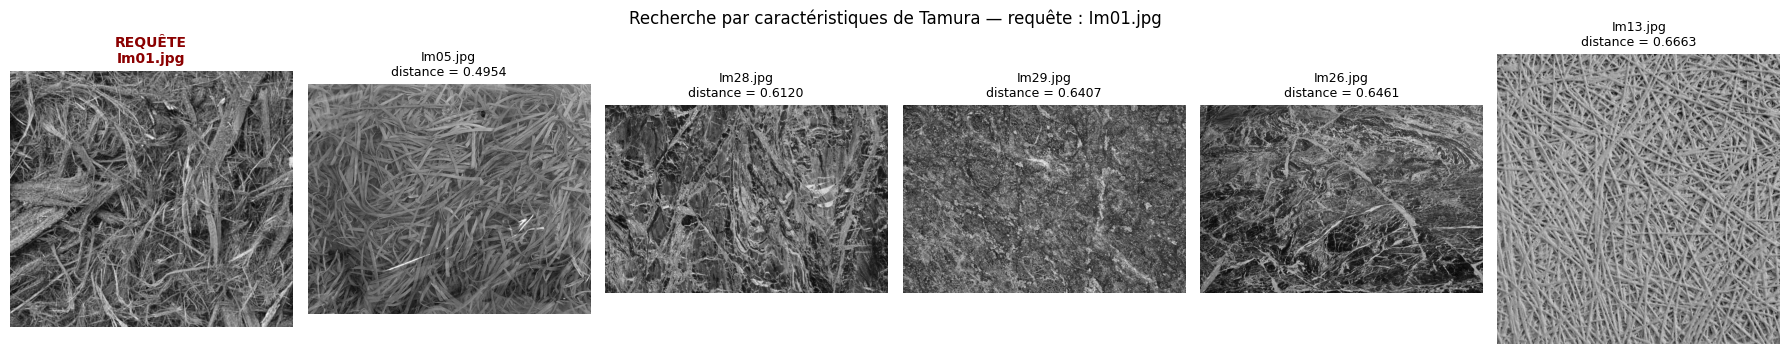


Requête : Im15.jpg
  1. Im25.jpg    distance = 0.1996
  2. Im12.jpg    distance = 0.4076
  3. Im27.jpg    distance = 0.5703
  4. Im28.jpg    distance = 0.7303
  5. Im24.jpg    distance = 0.8727
Mosaïque enregistrée : .\resultats\ex3_recherche\ex3_recherche_Im15.png


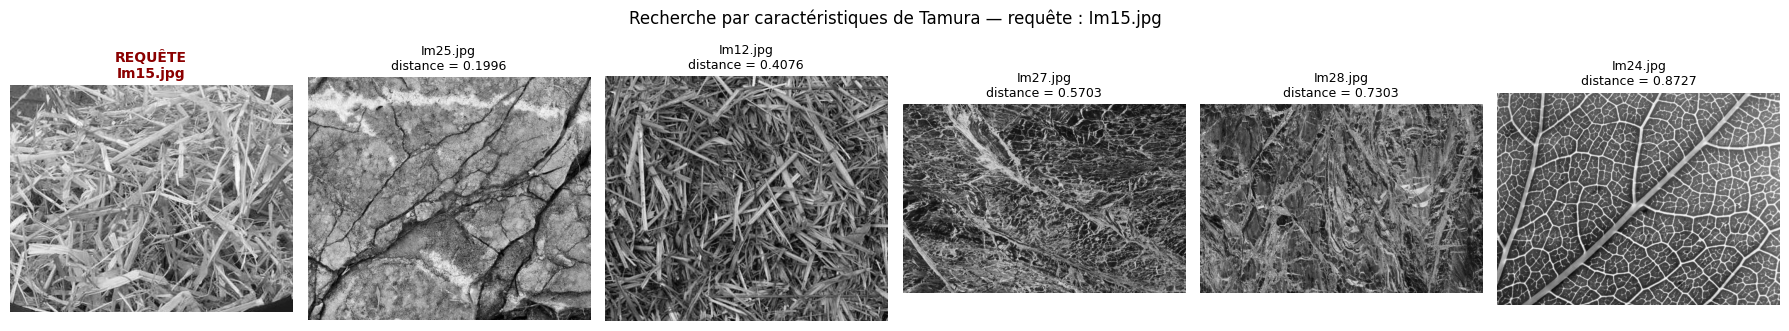


Requête : Im30.jpg
  1. Im13.jpg    distance = 0.3400
  2. Im29.jpg    distance = 0.6755
  3. Im05.jpg    distance = 0.6943
  4. Im31.jpg    distance = 0.7556
  5. Im01.jpg    distance = 0.8717
Mosaïque enregistrée : .\resultats\ex3_recherche\ex3_recherche_Im30.png


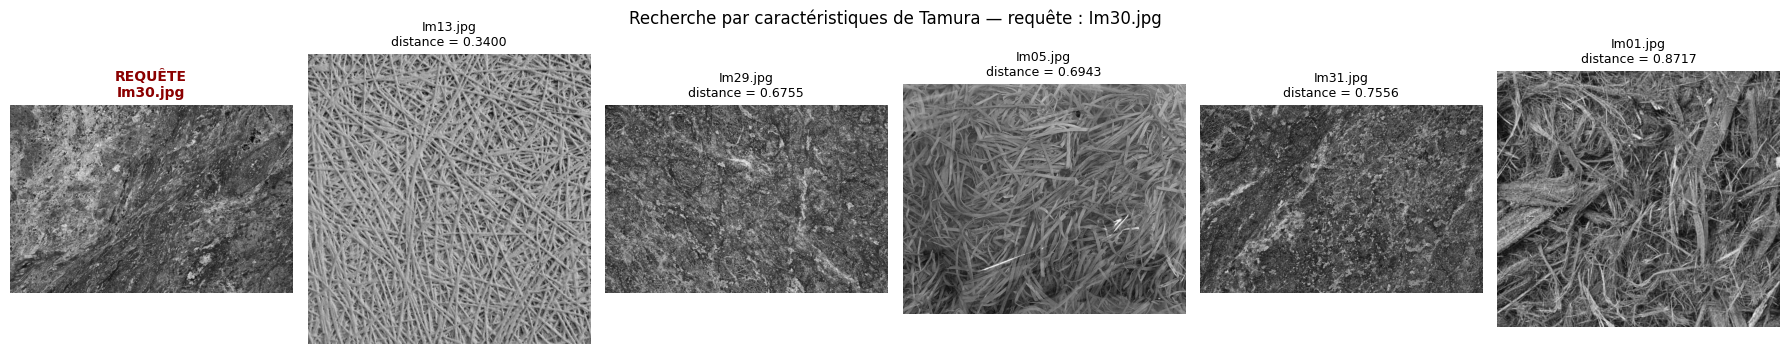

In [16]:
def afficher_resultats(nom_requete, resultats, sauvegarder=True):
    """Affiche la requête et les 5 images retrouvées avec leur distance."""
    # 1 colonne pour la requête + 5 colonnes pour les résultats
    fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))

    # --- Image requête (en grand, encadrée) ---
    chemin_requete = os.path.join(DOSSIER_TEXTURES, nom_requete)
    axes[0].imshow(charger_gris(chemin_requete), cmap="gray")
    axes[0].set_title(f"REQUÊTE\n{nom_requete}", fontsize=10, fontweight="bold",
                      color="darkred")
    axes[0].axis("off")
    for bord in axes[0].spines.values():
        bord.set_visible(True)

    # --- Les 5 images retrouvées ---
    for ax, (nom, distance) in zip(axes[1:], resultats):
        chemin = os.path.join(DOSSIER_TEXTURES, nom)
        ax.imshow(charger_gris(chemin), cmap="gray")
        ax.set_title(f"{nom}\ndistance = {distance:.4f}", fontsize=9)
        ax.axis("off")

    plt.suptitle(f"Recherche par caractéristiques de Tamura — requête : {nom_requete}",
                 fontsize=12)
    plt.tight_layout()

    if sauvegarder:
        radical = os.path.splitext(nom_requete)[0]
        chemin_png = os.path.join(DOSSIER_RECHERCHE, f"ex3_recherche_{radical}.png")
        plt.savefig(chemin_png, dpi=130)
        print(f"Mosaïque enregistrée : {chemin_png}")

    plt.show()


# --- Trois requêtes de démonstration ---
for requete in ["Im01.jpg", "Im15.jpg", "Im30.jpg"]:
    resultats = rechercher_similaires(requete, caracteristiques_brutes, noms_images, k=5)

    print(f"\n{'=' * 60}")
    print(f"Requête : {requete}")
    print("=" * 60)
    for rang, (nom, distance) in enumerate(resultats, start=1):
        print(f"  {rang}. {nom:10s}  distance = {distance:.4f}")

    afficher_resultats(requete, resultats)


## Étape 10 — Analyse et discussion

### Résultats obtenus

**Requête `Im01.jpg`** (foin grossier, clair) :

| Rang | Image | Distance |
|---|---|---|
| 1 | `Im05.jpg` | 0.4954 |
| 2 | `Im28.jpg` | 0.6120 |
| 3 | `Im29.jpg` | 0.6407 |
| 4 | `Im26.jpg` | 0.6461 |
| 5 | `Im13.jpg` | 0.6663 |

**Requête `Im15.jpg`** (paille claire sur pierre) :

| Rang | Image | Distance |
|---|---|---|
| 1 | `Im25.jpg` | 0.1996 |
| 2 | `Im12.jpg` | 0.4076 |
| 3 | `Im27.jpg` | 0.5703 |
| 4 | `Im28.jpg` | 0.7303 |
| 5 | `Im24.jpg` | 0.8727 |

**Requête `Im30.jpg`** (terre sombre granuleuse) :

| Rang | Image | Distance |
|---|---|---|
| 1 | `Im13.jpg` | 0.3400 |
| 2 | `Im29.jpg` | 0.6755 |
| 3 | `Im05.jpg` | 0.6943 |
| 4 | `Im31.jpg` | 0.7556 |
| 5 | `Im01.jpg` | 0.8717 |

### Interprétation

1. **Les résultats sont visuellement cohérents.** La requête `Im15` (paille sur pierre) retrouve `Im25` (pierre fissurée) avec une distance très faible de **0.1996** : les deux partagent une structure de blocs grossiers à fort contraste. La requête `Im30` (terre sombre) retrouve `Im13` puis `Im29` et `Im31`, qui sont toutes des textures de sol ou de matière granuleuse sombre.

2. **Les distances sont faibles (< 1)** pour les 5 résultats de chaque requête, ce qui indique que le descripteur à 4 dimensions capture effectivement la structure de texture. Un jeu de textures très hétérogènes produirait des distances de l'ordre de 2 à 3.

3. **La directionnalité est la caractéristique la plus discriminante** malgré sa faible amplitude (0 à 0.48) : elle sépare nettement les textures **fibreuses orientées** (`Im06` cheveux raides, `Im16/17/18/21` tissus tissés, valeurs 0.21 à 0.48) des textures **isotropes** (foin, paille, sol, valeurs < 0.02). C'est précisément le rôle du z-score : sans lui, cette caractéristique aurait été totalement ignorée face à la rudesse (4–27).

4. **La rudesse et le contraste jouent le rôle principal** dans le classement, car ce sont les caractéristiques les plus variables sur ce jeu (écarts-types de 6.03 et 8.82). Elles distinguent bien les textures grossières et contrastées (paille, pierre) des textures fines et douces.

5. **La granularité apporte une information complémentaire** mais redondante avec la rudesse : les deux sont issues du même profil d'échelles. On observe d'ailleurs que les images à forte rudesse (`Im02` : 26.8) ont tendance à avoir une granularité moyenne (5.0), car la rudesse mesure l'**amplitude** des variations alors que la granularité mesure leur **échelle**.

### Limites de la méthode

1. **Sensibilité à l'échelle** : la rudesse et la granularité sont exprimées en **pixels**. Deux textures identiques photographiées à des distances différentes auraient des valeurs différentes. C'est pourquoi les images n'ont pas été redimensionnées.
2. **Absence de sémantique** : les caractéristiques décrivent la structure, pas le contenu. Une texture de sable et une texture de gravier fin peuvent être proches sans être « le même objet ».
3. **Granularité non canonique** : la définition retenue est opérationnelle, pas standard. D'autres définitions (par exemple fondées sur les ondelettes de Gabor) donneraient des valeurs différentes.
4. **Directionnalité par entropie** : la formule de Tamura fondée sur les pics s'est révélée instable sur ce jeu (histogramme circulaire, double comptage du pic à 0 et π). L'entropie est plus robuste mais s'écarte de la formulation originale.
5. **Normalisation dépendante du corpus** : le z-score est calculé sur les 38 images. Ajouter une nouvelle image change la moyenne et l'écart-type, donc les distances. Les JSON contiennent heureusement les valeurs **brutes**, ce qui permet de recalculer.
6. **Pas d'information de couleur** : deux textures de même structure mais de couleurs opposées sont jugées identiques.

### Améliorations possibles

- **Ajouter les caractéristiques de couleur** des exercices 1 et 2 pour un descripteur hybride couleur + texture.
- Utiliser **plus d'échelles** ($k$ jusqu'à 6 ou 7) pour mieux capter les textures grossières.
- Implémenter la **directionnalité de Tamura originale** avec un vrai regroupement circulaire des pics, pour comparer avec l'entropie.
- Tester d'autres distances (Manhattan, cosinus) en plus de l'euclidienne.
- Évaluer la recherche quantitativement : si les images sont regroupées par famille, calculer la précision@5.

### Conclusion

Le système de recherche par caractéristiques de Tamura **fonctionne** sur ce jeu de 38 textures : les 5 images retrouvées pour chaque requête appartiennent visuellement à la même famille de texture, avec des distances faibles (0.20 à 0.87). Les quatre caractéristiques sont **complémentaires** — la rudesse et le contraste dominent le classement, la directionnalité isole les textures orientées, et la granularité affine la description de l'échelle.

Cette approche est **orthogonale aux exercices 1 et 2** : elle décrit la structure spatiale plutôt que la couleur. Combinée aux descripteurs colorimétriques, elle constituerait un système de recherche d'images bien plus complet.
